## Implementing a Feedforward Neural Network for Fashion-MNIST Classification in Keras

> **CHANGE:** This notebook uses Fashion-MNIST instead of CIFAR-10. The model and evaluation workflow are kept as close to the original as possible.

#### Understanding the Problem
We're tasked with creating a feedforward neural network with three hidden layers to classify images from the Fashion-MNIST dataset. Fashion-MNIST contains 70,000 grayscale images of clothing items, with 10 classes (60,000 training images and 10,000 test images).

In [1]:
# Import necessary libraries
import tensorflow as tf

# CHANGE: Use Fashion-MNIST instead of CIFAR-10
from tensorflow.keras.datasets import fashion_mnist

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
import numpy as np

#### Loading and Preprocessing the Data
- **CHANGE:** Load Fashion-MNIST instead of CIFAR-10.
- Pixel values are normalized to a range of 0-1 for better performance.
- Class labels are converted to one-hot encoded vectors for categorical cross-entropy loss.
- **CHANGE:** Fashion-MNIST images are grayscale and sized 28×28, rather than RGB 32×32.

In [2]:
# Loading and Preprocessing the Data

# CHANGE: Load Fashion-MNIST instead of CIFAR-10
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values to be between 0 and 1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Convert class vectors to binary class matrices
num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


#### Building the Feedforward Neural Network
- We create a Sequential model.
- **CHANGE:** The input layer flattens each 28×28 grayscale image into a 1D vector (784 features).
- Three hidden layers with 512, 256, and 128 neurons are added, using ReLU activation.
- Dropout layers are available to help prevent overfitting (currently commented out, as in the original).
- The output layer has 10 neurons (for 10 classes) with softmax activation for probability distribution.
- The model is compiled with categorical cross-entropy loss, Adam optimizer, and accuracy metric.

In [3]:
# Create the model
model = Sequential()

# CHANGE: Fashion-MNIST input shape is (28, 28), not (32, 32, 3)
model.add(Flatten(input_shape=(28, 28)))

# Hidden layers (unchanged)
model.add(Dense(512, activation='relu'))
# model.add(Dropout(0.2))
model.add(Dense(256, activation='relu'))
# model.add(Dropout(0.2))
model.add(Dense(128, activation='relu'))
# model.add(Dropout(0.2))


# Output layer
model.add(Dense(num_classes, activation='softmax'))

# Compile the model
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


#### Training the Model
- The model is trained with a batch size of 32.
- Validation data is used to monitor performance during training.
- The original 100-epoch setting is retained to minimize changes.

In [4]:
# Train the model
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(x_test, y_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8259 - loss: 0.4798 - val_accuracy: 0.8554 - val_loss: 0.4030
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 12ms/step - accuracy: 0.8663 - loss: 0.3613 - val_accuracy: 0.8480 - val_loss: 0.4252
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.8805 - loss: 0.3241 - val_accuracy: 0.8659 - val_loss: 0.3747
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.8877 - loss: 0.2998 - val_accuracy: 0.8715 - val_loss: 0.3533
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.8939 - loss: 0.2830 - val_accuracy: 0.8672 - val_loss: 0.3565
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.8971 - loss: 0.2722 - val_accuracy: 0.8751 - val_loss: 0.3605
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9040 - loss: 0.2572 - val_accuracy: 0.8846 - val_loss: 0.3315
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9072 -

#### Evaluating the Model
- The model is evaluated on the test set.
- Test accuracy is printed.

In [5]:
# Evaluate the model
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8899 - loss: 0.3301
Test accuracy: 0.8899000287055969


#### Creating a Confusion Matrix in Keras

Understanding the Confusion Matrix
    A confusion matrix is a performance evaluation metric that provides an overview of the accuracy of a classification model. It's a table with actual values in rows and predicted values in columns.
- We predict the probabilities for each class using the trained model.
- We convert the probabilities to class labels using argmax.


In [6]:
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

import seaborn as sns

In [7]:
# Make predictions on the test set
y_pred = model.predict(x_test)
# Convert probabilities to class labels
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


- We calculate the confusion matrix using sklearn.metrics.confusion_matrix.
- We visualize the confusion matrix using seaborn's heatmap.

Understanding the Confusion Matrix
- Each row represents the actual class.
- Each column represents the predicted class.
- The diagonal elements represent correctly classified instances.
- Off-diagonal elements represent misclassified instances.

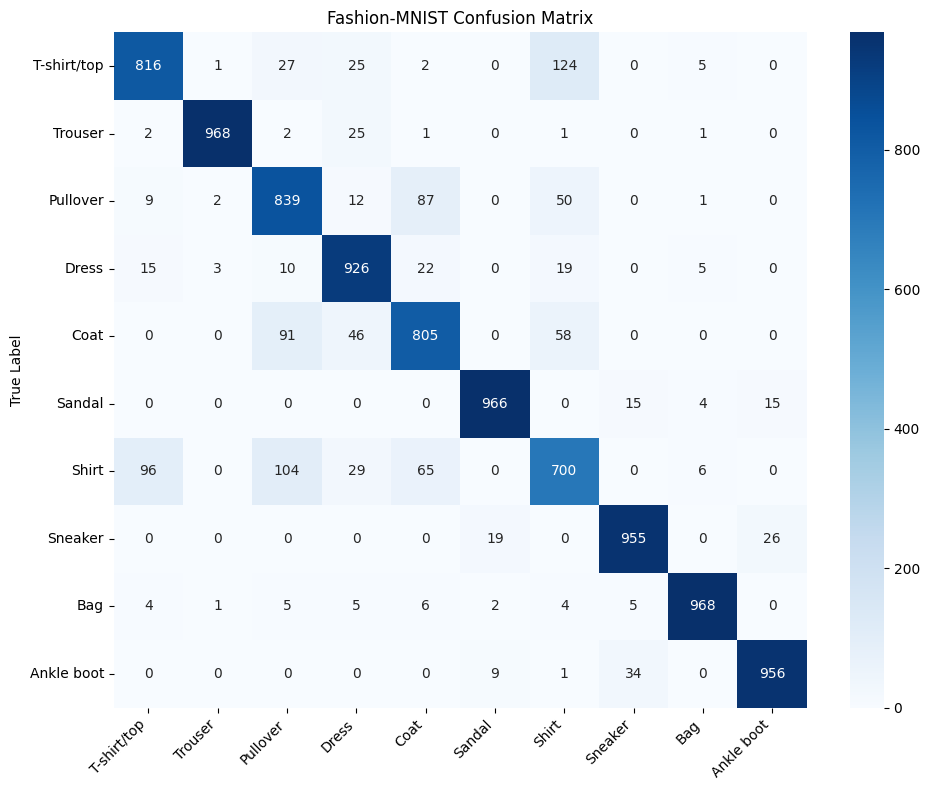

[[816   1  27  25   2   0 124   0   5   0]
 [  2 968   2  25   1   0   1   0   1   0]
 [  9   2 839  12  87   0  50   0   1   0]
 [ 15   3  10 926  22   0  19   0   5   0]
 [  0   0  91  46 805   0  58   0   0   0]
 [  0   0   0   0   0 966   0  15   4  15]
 [ 96   0 104  29  65   0 700   0   6   0]
 [  0   0   0   0   0  19   0 955   0  26]
 [  4   1   5   5   6   2   4   5 968   0]
 [  0   0   0   0   0   9   1  34   0 956]]


In [8]:
# CHANGE: Fashion-MNIST class names replace CIFAR-10 class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Compute the confusion matrix
confusion_mtx = confusion_matrix(y_true_classes, y_pred_classes)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
plt.xlabel('Predicted Label')
sns.heatmap(confusion_mtx, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel('True Label')
plt.title('Fashion-MNIST Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
print(confusion_mtx)

#### Plot Learning Curves

Training Loss vs. Validation Loss

- X-axis: Represents the number of epochs.
- Y-axis: Represents the loss value.
- Training loss: Shows how well the model fits the training data. It generally decreases as the model learns.
- Validation loss: Shows how well the model generalizes to unseen data. It's calculated on a validation set.
    
Ideal scenario:

- Both training and validation loss decrease steadily.
- The gap between the two curves is small.

Overfitting:

- Training loss continues to decrease, but validation loss starts to increase or plateau.
- This indicates the model is learning the training data too well and is not generalizing well to new data.

Underfitting:

- Both training and validation loss are high and plateau early.
- This indicates the model is not complex enough to capture the underlying patterns in the data.

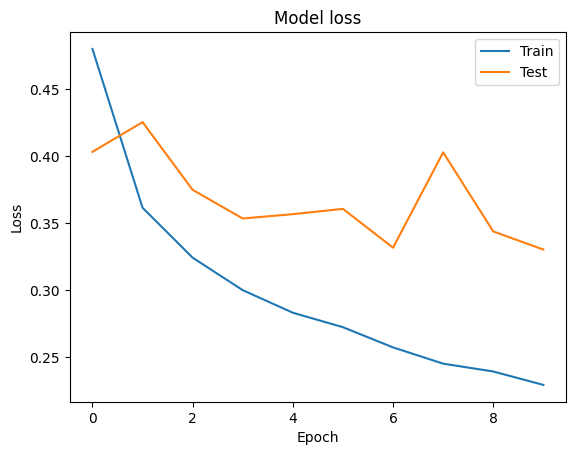

In [9]:
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper right')
plt.show()

Training Accuracy vs. Validation Accuracy

- X-axis: Represents the number of epochs.
- Y-axis: Represents the accuracy value.
- Training accuracy: Shows how accurately the model predicts on the training data.
- Validation accuracy: Shows how accurately the model predicts on unseen data.

Ideal scenario:

- Both training and validation accuracy increase steadily.
- The gap between the two curves is small.

Overfitting:

- Training accuracy continues to increase, but validation accuracy plateaus or decreases.
- This indicates the model is memorizing the training data instead of learning general patterns.

Underfitting:

- Both training and validation accuracy are low and plateau early.
- This indicates the model is not complex enough to learn the underlying patterns in the data.

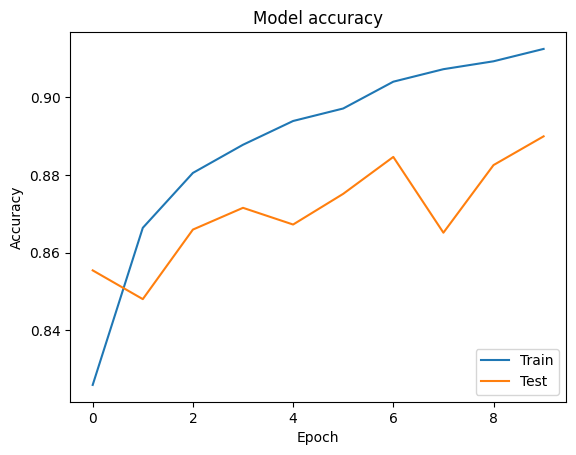

In [10]:

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='lower right')
plt.show()